# Normal vs. Defective Image Classification with a CNN

This notebook trains a binary CNN classifier using the prepared train/validation folders. The requested split is **2,300 Normal + 3,006 Defective for training** and **575 Normal + 752 Defective for validation**.

Expected folders are `Data/Image/train/{normal,defective}` and `Data/Image/validation/{normal,defective}`. The notebook reads the saved split directly and checks that every class folder contains the expected number of images.

It trains the CNN, VGG16, and MobileNetV2, then saves only the top validation performer (defective-class F1, accuracy as tie-breaker) to `models/best_image_classifier.keras`.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
IMAGE_SIZE = (128, 128)
BATCH_SIZE = 32
EPOCHS = 25

# Resolve paths whether this notebook is started from the project root or Notebooks/.
BASE_DIR = Path.cwd().resolve()
if not (BASE_DIR / "Data").is_dir() and (BASE_DIR.parent / "Data").is_dir():
    BASE_DIR = BASE_DIR.parent
IMAGE_DIR = BASE_DIR / "Data" / "Image"

if not IMAGE_DIR.is_dir():
    raise FileNotFoundError(f"Image folder not found: {IMAGE_DIR}")

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".gif"}
requested_counts = {
    "Normal": {"train": 2300, "validation": 575},
    "Defective": {"train": 3006, "validation": 752},
}
class_directory_names = {"Normal": "normal", "Defective": "defective"}
split_records = []
for class_name, directory_name in class_directory_names.items():
    for split_name in ("train", "validation"):
        class_dir = IMAGE_DIR / split_name / directory_name
        if not class_dir.is_dir():
            raise FileNotFoundError(f"Missing {split_name} {class_name} folder: {class_dir}")
        image_paths = sorted(
            path for path in class_dir.rglob("*")
            if path.is_file() and path.suffix.casefold() in image_extensions
        )
        expected = requested_counts[class_name][split_name]
        if len(image_paths) != expected:
            raise ValueError(
                f"Expected {expected} {split_name} {class_name} images in {class_dir}, "
                f"found {len(image_paths)}. Run the dataset split step first."
            )
        split_records.extend(
            (str(path), 0 if class_name == "Normal" else 1, split_name, class_name)
            for path in image_paths
        )

for split_name in ("train", "validation"):
    print(f"{split_name.title()} counts:")
    for class_name in ("Normal", "Defective"):
        actual = sum(
            record[2] == split_name and record[3] == class_name
            for record in split_records
        )
        expected = requested_counts[class_name][split_name]
        print(f"  {class_name}: {actual}")
        assert actual == expected, (
            f"Expected {expected} {class_name} images in {split_name}, got {actual}."
        )

train_records = [record for record in split_records if record[2] == "train"]
validation_records = [record for record in split_records if record[2] == "validation"]
train_paths = {record[0] for record in train_records}
validation_paths = {record[0] for record in validation_records}
assert train_paths.isdisjoint(validation_paths), "An image was assigned to both splits."

print(f"Total training images: {len(train_records)}")
print(f"Total validation images: {len(validation_records)}")


Train counts:
  Normal: 2300
  Defective: 3006
Validation counts:
  Normal: 575
  Defective: 752
Total training images: 5306
Total validation images: 1327


In [2]:
AUTOTUNE = tf.data.AUTOTUNE


def load_image(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMAGE_SIZE)
    return image, label


def make_dataset(records, training=False):
    paths = [record[0] for record in records]
    labels = np.asarray([record[1] for record in records], dtype=np.float32)
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        dataset = dataset.shuffle(len(records), seed=SEED, reshuffle_each_iteration=True)
    return dataset.map(load_image, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_records, training=True)
validation_ds = make_dataset(validation_records)

model = keras.Sequential([
    layers.Input(shape=(*IMAGE_SIZE, 3)),
    layers.Rescaling(1.0 / 255),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid"),
], name="CNN")

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", keras.metrics.Precision(name="precision"), keras.metrics.Recall(name="recall")],
)
model.summary()


Model: "CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,569 (396.75 KB)

 Trainable params: 101,569 (396.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25


c:\Users\nihaa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


166/166 ━━━━━━━━━━━━━━━━━━━━ 35s 196ms/step - accuracy: 0.5273 - loss: 0.6937 - precision: 0.5747 - recall: 0.6374 - val_accuracy: 0.7347 - val_loss: 0.6920 - val_precision: 0.7717 - val_recall: 0.7553
Epoch 2/25
166/166 ━━━━━━━━━━━━━━━━━━━━ 32s 190ms/step - accuracy: 0.6140 - loss: 0.6689 - precision: 0.6551 - recall: 0.6730 - val_accuracy: 0.4303 - val_loss: 0.7665 - val_precision: 0.4714 - val_recall: 0.0439
Epoch 3/25
166/166 ━━━━━━━━━━━━━━━━━━━━ 34s 207ms/step - accuracy: 0.7015 - loss: 0.5934 - precision: 0.7481 - recall: 0.7132 - val_accuracy: 0.7641 - val_loss: 0.5246 - val_precision: 0.7447 - val_recall: 0.8883
Epoch 4/25
166/166 ━━━━━━━━━━━━━━━━━━━━ 38s 187ms/step - accuracy: 0.7998 - loss: 0.4636 - precision: 0.8347 - recall: 0.8064 - val_accuracy: 0.8757 - val_loss: 0.3748 - val_precision: 0.9495 - val_recall: 0.8245
Epoch 5/25
166/166 ━━━━━━━━━━━━━━━━━━━━ 33s 199ms/step - accuracy: 0.8611 - loss: 0.3629 - precision: 0.8965 - recall: 0.8533 - val_accuracy: 0.9224 - val_loss

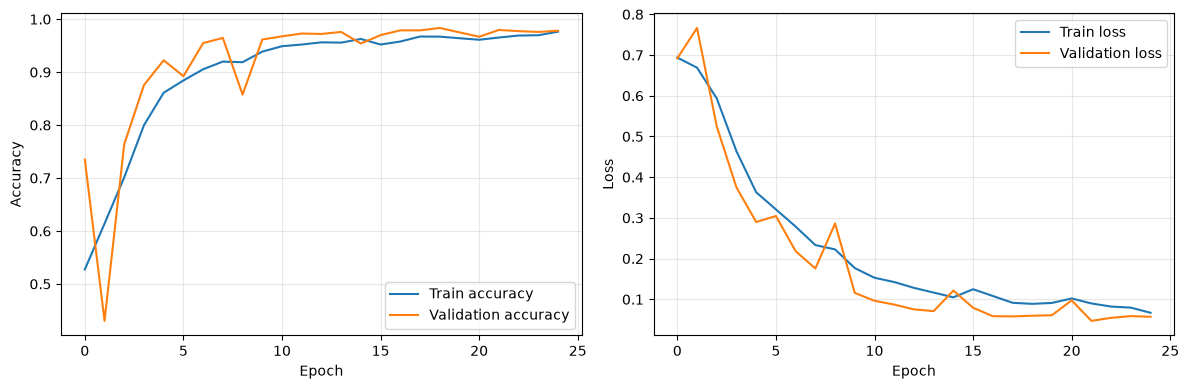

In [3]:
# Weight classes so the slightly larger Defective class does not dominate training.
train_label_counts = np.bincount([record[1] for record in train_records], minlength=2)
class_weight = {
    class_id: len(train_records) / (2.0 * count)
    for class_id, count in enumerate(train_label_counts)
}

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
]

history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=EPOCHS,
    class_weight=class_weight,
    callbacks=callbacks,
)

results = model.evaluate(validation_ds, return_dict=True, verbose=0)
print("Validation metrics:")
for metric, value in results.items():
    print(f"  {metric}: {value:.4f}")

true_labels = np.concatenate([labels.numpy() for _, labels in validation_ds]).astype(np.int32)
probabilities = model.predict(validation_ds, verbose=0).ravel()
predicted_labels = (probabilities >= 0.5).astype(np.int32)
confusion = tf.math.confusion_matrix(true_labels, predicted_labels, num_classes=2).numpy()
print("Confusion matrix (rows=true, columns=predicted; Normal, Defective):")
print(confusion)

plt.figure(figsize=(12, 4))
for index, metric in enumerate(("accuracy", "loss"), start=1):
    plt.subplot(1, 2, index)
    plt.plot(history.history[metric], label=f"Train {metric}")
    plt.plot(history.history[f"val_{metric}"], label=f"Validation {metric}")
    plt.xlabel("Epoch")
    plt.ylabel(metric.title())
    plt.legend()
    plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [4]:
# Calculate validation scores from the confusion matrix.
# Rows are true labels and columns are predicted labels: Normal, Defective.
tn, fp, fn, tp = confusion.ravel()

evaluation_scores = {
    "Accuracy": (tp + tn) / (tp + tn + fp + fn),
    "Precision (Defective)": tp / (tp + fp) if tp + fp else 0.0,
    "Recall (Defective)": tp / (tp + fn) if tp + fn else 0.0,
}

evaluation_scores["F1 score (Defective)"] = (
    2 * evaluation_scores["Precision (Defective)"] * evaluation_scores["Recall (Defective)"]
    / (evaluation_scores["Precision (Defective)"] + evaluation_scores["Recall (Defective)"])
    if evaluation_scores["Precision (Defective)"] + evaluation_scores["Recall (Defective)"]
    else 0.0
)

cnn_scores = {
    "accuracy": evaluation_scores["Accuracy"],
    "precision": evaluation_scores["Precision (Defective)"],
    "recall": evaluation_scores["Recall (Defective)"],
    "f1": evaluation_scores["F1 score (Defective)"],
}

print("Validation scores:")
for metric_name, score in evaluation_scores.items():
    print(f"{metric_name}: {score:.2%}")


Validation scores:
Accuracy: 97.97%
Precision (Defective): 98.40%
Recall (Defective): 98.01%
F1 score (Defective): 98.20%


## Predict one image

Run this cell after training. Replace the sample path with any image you want to classify.


In [5]:
sample_path = validation_records[0][0]
image = keras.utils.load_img(sample_path, target_size=IMAGE_SIZE)
image_array = keras.utils.img_to_array(image)[None, ...]
defective_probability = float(model.predict(image_array, verbose=0)[0, 0])
predicted_class = "Defective" if defective_probability >= 0.5 else "Normal"
print(f"Image: {sample_path}")
print(f"Prediction: {predicted_class} (Defective probability: {defective_probability:.3f})")


Image: D:\Guvi\Ferro Vision\Data\Image\train\normal\cast_ok_0_157.jpeg
Prediction: Normal (Defective probability: 0.001)


## Pretrained CNN models: VGG16 and MobileNetV2

The following transfer-learning models use the same `train_records` and `validation_records` split created above. Each ImageNet backbone stays frozen while its binary classifier head is trained. The first run may download ImageNet weights and requires internet access. These models are additional to the CNN above.


In [6]:
# Keep transfer-learning settings and names separate from the CNN above.
PT_IMAGE_SIZE = (128, 128)
PT_BATCH_SIZE = 32
PT_EPOCHS = 10
PT_AUTOTUNE = tf.data.AUTOTUNE

if "train_records" not in globals() or "validation_records" not in globals():
    raise RuntimeError("Run the data-splitting cell above before training pretrained models.")


def pt_make_dataset(records, preprocess_fn, training=False):
    paths = [record[0] for record in records]
    labels = np.asarray([record[1] for record in records], dtype=np.float32)
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        dataset = dataset.shuffle(
            len(records), seed=SEED, reshuffle_each_iteration=True
        )

    def load_and_preprocess(path, label):
        image_bytes = tf.io.read_file(path)
        image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
        image.set_shape([None, None, 3])
        image = tf.image.resize(image, PT_IMAGE_SIZE)
        image = preprocess_fn(image)
        return image, tf.expand_dims(label, axis=-1)

    return (
        dataset.map(load_and_preprocess, num_parallel_calls=PT_AUTOTUNE)
        .batch(PT_BATCH_SIZE)
        .prefetch(PT_AUTOTUNE)
    )


def pt_build_model(backbone, model_name):
    backbone.trainable = False
    inputs = keras.Input(shape=(*PT_IMAGE_SIZE, 3), name="preprocessed_image")
    features = backbone(inputs, training=False)
    features = layers.GlobalAveragePooling2D()(features)
    features = layers.Dropout(0.3)(features)
    features = layers.Dense(128, activation="relu")(features)
    features = layers.Dropout(0.2)(features)
    outputs = layers.Dense(1, activation="sigmoid", name="defective_probability")(features)
    model = keras.Model(inputs, outputs, name=model_name)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
        ],
    )
    return model


def pt_train_and_evaluate(model_name, backbone, preprocess_fn):
    train_ds = pt_make_dataset(train_records, preprocess_fn, training=True)
    validation_ds = pt_make_dataset(validation_records, preprocess_fn)
    model = pt_build_model(backbone, model_name)

    label_counts = np.bincount([record[1] for record in train_records], minlength=2)
    class_weights = {
        class_id: len(train_records) / (2.0 * count)
        for class_id, count in enumerate(label_counts)
    }

    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=3, restore_best_weights=True
        ),
    ]
    model.fit(
        train_ds,
        validation_data=validation_ds,
        epochs=PT_EPOCHS,
        class_weight=class_weights,
        callbacks=callbacks,
        shuffle=False,
    )

    # EarlyStopping restores the best validation-loss weights in memory.
    y_true = np.concatenate([labels.numpy().ravel() for _, labels in validation_ds])
    probabilities = model.predict(validation_ds, verbose=0).ravel()
    y_pred = (probabilities >= 0.5).astype(np.int32)
    tn, fp, fn, tp = tf.math.confusion_matrix(
        y_true, y_pred, num_classes=2
    ).numpy().ravel()
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    scores = {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "confusion_matrix": np.array([[tn, fp], [fn, tp]]),
    }

    print(f"\n{model_name} validation scores:")
    print(f"Accuracy:  {accuracy:.2%}")
    print(f"Precision: {precision:.2%}")
    print(f"Recall:    {recall:.2%}")
    print(f"F1 score:  {f1:.2%}")
    print("Confusion matrix (rows=true, columns=predicted; Normal, Defective):")
    print(scores["confusion_matrix"])
    print("Best validation-loss weights retained in memory.")
    return model, scores


### VGG16 (ImageNet pretrained)

Run this cell to train the VGG16 classification head. The ImageNet backbone remains frozen.


In [7]:
vgg16_backbone = keras.applications.VGG16(
    include_top=False,
    weights="imagenet",
    input_shape=(*PT_IMAGE_SIZE, 3),
)
vgg16_model, vgg16_scores = pt_train_and_evaluate(
    "VGG16",
    vgg16_backbone,
    keras.applications.vgg16.preprocess_input,
)


Epoch 1/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 316s 2s/step - accuracy: 0.9203 - loss: 0.2700 - precision: 0.9440 - recall: 0.9135 - val_accuracy: 0.9902 - val_loss: 0.0496 - val_precision: 1.0000 - val_recall: 0.9827
Epoch 2/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 330s 2s/step - accuracy: 0.9908 - loss: 0.0426 - precision: 0.9980 - recall: 0.9857 - val_accuracy: 0.9887 - val_loss: 0.0400 - val_precision: 1.0000 - val_recall: 0.9801
Epoch 3/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 305s 2s/step - accuracy: 0.9917 - loss: 0.0311 - precision: 0.9973 - recall: 0.9880 - val_accuracy: 0.9962 - val_loss: 0.0226 - val_precision: 0.9973 - val_recall: 0.9960
Epoch 4/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 300s 2s/step - accuracy: 0.9911 - loss: 0.0309 - precision: 0.9980 - recall: 0.9864 - val_accuracy: 0.9962 - val_loss: 0.0172 - val_precision: 0.9973 - val_recall: 0.9960
Epoch 5/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 290s 2s/step - accuracy: 0.9930 - loss: 0.0238 - precision: 0.9977 - recall: 0.9900 - val_accuracy: 0.9962 - val_los

### MobileNetV2 (ImageNet pretrained)

Run this cell to train the MobileNetV2 classification head. The ImageNet backbone remains frozen.


In [8]:
mobilenetv2_backbone = keras.applications.MobileNetV2(
    include_top=False,
    weights="imagenet",
    input_shape=(*PT_IMAGE_SIZE, 3),
)
mobilenetv2_model, mobilenetv2_scores = pt_train_and_evaluate(
    "MobileNetV2",
    mobilenetv2_backbone,
    keras.applications.mobilenet_v2.preprocess_input,
)


Epoch 1/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 30s 166ms/step - accuracy: 0.9291 - loss: 0.1836 - precision: 0.9525 - recall: 0.9208 - val_accuracy: 0.8990 - val_loss: 0.2235 - val_precision: 1.0000 - val_recall: 0.8218
Epoch 2/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 24s 143ms/step - accuracy: 0.9787 - loss: 0.0672 - precision: 0.9885 - recall: 0.9737 - val_accuracy: 0.9819 - val_loss: 0.0700 - val_precision: 0.9986 - val_recall: 0.9694
Epoch 3/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 24s 146ms/step - accuracy: 0.9883 - loss: 0.0426 - precision: 0.9943 - recall: 0.9850 - val_accuracy: 0.9887 - val_loss: 0.0384 - val_precision: 0.9933 - val_recall: 0.9867
Epoch 4/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 24s 143ms/step - accuracy: 0.9900 - loss: 0.0328 - precision: 0.9960 - recall: 0.9864 - val_accuracy: 0.9902 - val_loss: 0.0329 - val_precision: 0.9973 - val_recall: 0.9854
Epoch 5/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 24s 142ms/step - accuracy: 0.9908 - loss: 0.0307 - precision: 0.9937 - recall: 0.9900 - val_accuracy: 0.9864

In [9]:
model_candidates = {
    "CNN": {"model": model, **cnn_scores},
    "VGG16": {"model": vgg16_model, **vgg16_scores},
    "MobileNetV2": {"model": mobilenetv2_model, **mobilenetv2_scores},
}
print("Validation comparison (ranked by defective-class F1):")
print(f"{'Model':<16} {'Accuracy':>10} {'Precision':>12} {'Recall':>10} {'F1':>10}")
for model_name, scores in model_candidates.items():
    print(
        f"{model_name:<16} {scores['accuracy']:>9.2%} "
        f"{scores['precision']:>11.2%} {scores['recall']:>9.2%} "
        f"{scores['f1']:>9.2%}"
    )

best_model_name = max(
    model_candidates,
    key=lambda name: (
        model_candidates[name]["f1"],
        model_candidates[name]["accuracy"],
    ),
)
best_model = model_candidates[best_model_name]["model"]
best_model_path = BASE_DIR / "models" / "best_image_classifier.keras"
best_model_path.parent.mkdir(parents=True, exist_ok=True)
best_model.save(best_model_path)

print(f"\nBest model: {best_model_name}")
print(f"Defective-class F1: {model_candidates[best_model_name]['f1']:.2%}")
print(f"Saved the single winning image model to: {best_model_path}")


Validation comparison (ranked by defective-class F1):
Model              Accuracy    Precision     Recall         F1
CNN                 97.97%      98.40%    98.01%    98.20%
VGG16               99.55%      99.60%    99.60%    99.60%
MobileNetV2         99.25%      99.20%    99.47%    99.34%

Best model: VGG16
Defective-class F1: 99.60%
Saved the single winning image model to: D:\Guvi\Ferro Vision\models\best_image_classifier.keras


### Predict with the saved best model

Run the comparison cell above first to save the winner. This helper reloads that single model and applies the matching preprocessing.


In [10]:
def predict_with_best_model(model, image_path):
    model_name = model.name
    image = keras.utils.load_img(image_path, target_size=PT_IMAGE_SIZE)
    image_array = keras.utils.img_to_array(image)
    if model_name == "VGG16":
        image_array = keras.applications.vgg16.preprocess_input(image_array)
    elif model_name == "MobileNetV2":
        image_array = keras.applications.mobilenet_v2.preprocess_input(image_array)
    elif model_name != "CNN":
        raise ValueError(f"Unsupported saved model name: {model_name}.")

    defective_probability = float(
        model.predict(image_array[None, ...], verbose=0)[0, 0]
    ) 
    predicted_class = "Defective" if defective_probability >= 0.5 else "Normal"
    print(f"Model: {model_name}")
    print(f"Prediction: {predicted_class}")
    print(f"Defective probability: {defective_probability:.2%}")
    return predicted_class, defective_probability

best_model = keras.models.load_model(BASE_DIR / "models" / "best_image_classifier.keras")
# Example: predict an existing validation image with the saved winner.
image_path = validation_records[0][0]
predict_with_best_model(best_model, image_path)


Model: VGG16
Prediction: Normal
Defective probability: 0.56%


('Normal', 0.005551427602767944)